In [1]:
import os # Configure which GPU

if os.getenv("CUDA_VISIBLE_DEVICES") is None:
    gpu_num = 0 # Use "" to use the CPU
    os.environ["CUDA_VISIBLE_DEVICES"] = f"{gpu_num}"
    os.environ["CUDA_VISIBLE_DEVICES"] = "1"
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'

# Import Sionna
try:
    import sionna
except ImportError as e:
    # Install Sionna if package is not already installed
    import os
    os.system("pip install sionna")
    import sionna

# Configure the notebook to use only a single GPU and allocate only as much memory as needed
# For more details, see https://www.tensorflow.org/guide/gpu
import tensorflow as tf
gpus = tf.config.list_physical_devices('GPU')
if gpus:
    try:
        tf.config.experimental.set_memory_growth(gpus[0], True)
    except RuntimeError as e:
        print(e)
# Avoid warnings from TensorFlow
tf.get_logger().setLevel('ERROR')

# Colab does currently not support the latest version of ipython.
# Thus, the preview does not work in Colab. However, whenever possible we
# strongly recommend to use the scene preview mode.
try: # detect if the notebook runs in Colab
    import google.colab
    no_preview = True # deactivate preview
except:
    if os.getenv("SIONNA_NO_PREVIEW"):
        no_preview = True
    else:
        no_preview = False

resolution = [480,320] # increase for higher quality of renderings

import matplotlib.pyplot as plt
import numpy as np
import time
import pandas as pd



# Import Sionna RT components
from sionna.rt import load_scene, Transmitter, Receiver, PlanarArray, Camera, Paths

# For link-level simulations
from sionna.channel import cir_to_ofdm_channel, subcarrier_frequencies, OFDMChannel, ApplyOFDMChannel, CIRDataset
from sionna.nr import PUSCHConfig, PUSCHTransmitter, PUSCHReceiver
from sionna.utils import compute_ber, ebnodb2no, PlotBER

from nr_pusch.model import Model, CIRGenerator, PUSCHModel
from nr_pusch.configs import SISOConfig, MIMOConfig

# Set random seed for reproducibility
sionna.config.seed = 42
tf.random.set_seed(42)
np.random.seed(42)

In [2]:
# Load integrated scene
scene = load_scene(sionna.rt.scene.munich) # Try also sionna.rt.scene.etoile


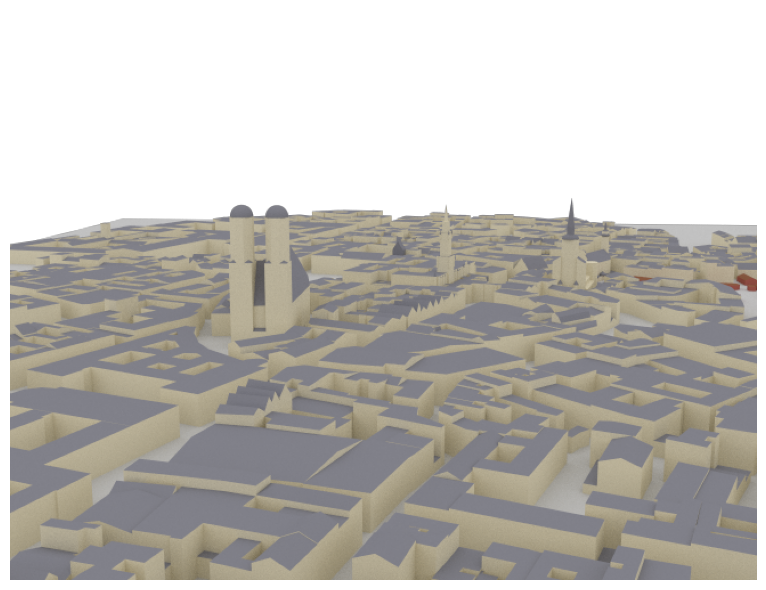

In [3]:
# Render scene
if no_preview:
    scene.render(camera="scene-cam-0", num_samples=512);

# The preview camera can be directly rendered as high-quality image (option only available in local mode)
if not no_preview:
    scene.preview()
    scene.render(camera="preview", num_samples=512);
else:
    print("Function not available in Colab mode.")

In [4]:
# Create new camera with different configuration
my_cam = Camera("my_cam", position=[-250,250,150], look_at=[-15,30,28])
scene.add(my_cam)

# # Render scene with new camera*
# scene.render("my_cam", resolution=resolution, num_samples=512); # Increase num_samples to increase image quality

In [5]:
# System parameters
subcarrier_spacing = 15e3
num_time_steps = 14 # Total number of ofdm symbols per slot

num_tx = 1
num_rx = 1 
num_tx_ant = 1
num_rx_ant = 1

# batch_size for CIR generation
batch_size_cir = 1000
# batch_size_cir = 1000

los_generation = input("Do you want to generate LOS data? (y/n): ")
if los_generation == "y":
    los = True
else:
    los = False
los_generation_test = input("Do you want to generate LOS data for testing? (y/n): ")
if los_generation_test == "y":
    los_test = True
else:
    los_test = False
nlos_generation = input("Do you want to generate NLOS data? (y/n): ")
if nlos_generation == "y":
    nlos = True
else:
    nlos = False
nlos_generation_test = input("Do you want to generate NLOS data for testing? (y/n): ")
if nlos_generation_test == "y":
    nlos_test = True
else:
    nlos_test = False


In [6]:
scene.synthetic_array = (
    True  # Emulate multiple antennas to reduce ray tracing complexity
)
scene.frequency = 2.14e9 # in Hz; implicitly updates RadioMaterials
# Transmitter (=basestation) has an antenna pattern from 3GPP 38.901
scene.tx_array = PlanarArray(
    num_rows=1,
    num_cols=1,
    vertical_spacing=0.5,
    horizontal_spacing=0.5,
    pattern="tr38901",
    polarization="V",
)

# Create transmitter
tx = Transmitter(
    name="tx", position=[8.5, 21, 27], look_at=[45, 90, 1.5]
)  # optional, defines view direction
scene.add(tx)

# Configure antenna array for all receivers (=UEs)
scene.rx_array = PlanarArray(
    num_rows=1,
    num_cols=1,
    vertical_spacing=0.5,
    horizontal_spacing=0.5,
    pattern="tr38901",  # UE orientation is random
    polarization="V",
)

In [7]:
max_depth = 5 # Defines max number of ray interactions

min_gain_db = -130 # in dB; ignore any position with less than -130 dB path gain
max_gain_db = 0 # in dB; ignore strong paths

# sample points in a 5-400m radius around the receiver
min_dist = 5 # in m
max_dist = 400 # in m
cm = scene.coverage_map(max_depth=max_depth,
                        diffraction=True,
                        cm_cell_size=(1., 1.),
                        combining_vec=None,
                        precoding_vec=None,
                        num_samples=int(5e4))
                        # num_samples=int(20e6))
#sample batch_size random user positions from coverage map
ue_pos, _ = cm.sample_positions(num_pos=batch_size_cir,
                                metric="path_gain",
                                min_val_db=min_gain_db,
                                max_val_db=max_gain_db,
                                min_dist=min_dist,
                                max_dist=max_dist)
ue_pos = tf.squeeze(ue_pos)

# # Create batch_size receivers
for i in range(batch_size_cir):
    rx = Receiver(name=f"rx-{i}",
                  position=ue_pos[i], # Random position sampled from coverage map
                  )
    scene.add(rx)

In [8]:
scene.preview(show_devices=True, coverage_map=cm)

Renderer(camera=PerspectiveCamera(aspect=1.31, children=(DirectionalLight(intensity=0.25, matrixWorldNeedsUpda…

In [8]:
target_num_cirs = 1000 # Defines how many different CIRS are generated.
# Remark: some path are removed if no path was found for this position

max_depth = 5
min_gain_db = -130 # in dB / ignore any position with less than -130 dB path gain
max_gain_db = 0 # in dB / ignore any position with more than 0 dB path gain

# Sample points within a 10-400m radius around the transmitter
min_dist = 10 # in m
max_dist = 400 # in m



MU-MIMO

In [9]:
num_samples_per_scenario = 2000
batch_size = 1  # Must be the same for the BER simulations as CIRDataset returns fixed batch_size
ebno_step_size = 1000
num_test_samples = 1000
siso_configuration = SISOConfig(
    num_prb=16,
    mcs_index=14,
    num_layers=1,
    mcs_table=2,
    domain="freq",
    num_tx_ant=num_tx_ant,
    num_tx=num_tx,
    subcarrier_spacing=subcarrier_spacing,
    num_rx_ant=num_rx_ant,
    num_rx=num_rx,
    num_symbols=num_time_steps,
    batch_size=batch_size,
    num_paths=23,
)
ebno_min = -3
ebno_max = 19


if nlos or nlos_test:
    # Placeholder to gather channel impulse reponses
    a = None
    tau = None

    # Each simulation returns batch_size_cir results
    num_runs = int(np.ceil(target_num_cirs/batch_size_cir))
    for idx in range(num_runs):
        print(f"Progress: {idx+1}/{num_runs}", end="\r")
        # Sample random user positions
        ue_pos, _ = cm.sample_positions(
            num_pos=batch_size_cir,
            metric="path_gain",
            min_val_db=min_gain_db,
            max_val_db=max_gain_db,
            min_dist=min_dist,
            max_dist=max_dist,
        )
        ue_pos = tf.squeeze(ue_pos)

        # Update all receiver positions
        for idx in range(batch_size_cir):
            scene.receivers[f"rx-{idx}"].position = ue_pos[idx]

        # Simulate CIR
        paths = scene.compute_paths(
            max_depth=max_depth,
            # diffraction=True,
            los=False,
            # method="exhaustive",
            reflection=True,
            diffraction=True,
            scattering=True,
            scat_keep_prob=0.15,
            edge_diffraction=True,
            num_samples=5e4,
            # num_samples=1e6,
        )  # shared between all tx in a scene
        # paths.reverse_direction = True  # Convert to uplink hwdirection
        paths.apply_doppler(
            sampling_frequency=subcarrier_spacing,
            num_time_steps=14,
            # tx_velocities=[np.random.uniform(0, 10), np.random.uniform(0, 10), 0],
            tx_velocities=[0, 0, 0],
            rx_velocities=[np.random.uniform(0, 10), np.random.uniform(0, 10), 0],
        )
        # Transform paths into channel impulse responses

        a_, tau_ = paths.cir(los=False)
        print("Shape of a_:", a_.shape)
        print("Shape of tau_:", tau_.shape)
        if a is None:
            a = a_.numpy()
            tau = tau_.numpy()
        else:
            # Concatenate along the num_tx dimension
            a = np.concatenate([a, a_], axis=3)
            tau = np.concatenate([tau, tau_], axis=2)

    # Exchange the num_tx and batchsize dimensions
    # a = np.transpose(a, [3, 1, 2, 0, 4, 5, 6])
    a = np.transpose(a, [1, 0, 2, 3, 4, 5, 6])
    # tau = np.transpose(tau, [2, 1, 0, 3])
    tau = np.transpose(tau, [1, 0, 2, 3])

    # Remove CIRs that have no active link (i.e., a is all-zero)
    p_link = np.sum(np.abs(a) ** 2, axis=(1, 2, 3, 4, 5, 6))
    a = a[p_link > 0.0, ...]
    tau = tau[p_link > 0.0, ...]
    print("Shape of a:", a.shape)
    print("Shape of tau: ", tau.shape)


Shape of a_: (1, 1000, 1, 1, 1, 2327, 14)
Shape of tau_: (1, 1000, 1, 2327)
Shape of a: (998, 1, 1, 1, 1, 2327, 14)
Shape of tau:  (998, 1, 1, 2327)


NLOS Scenario

In [11]:
if nlos:
    dataset_nlos = []
    # Loop through the number of samples per Eb/No value
    for sample_idx in range(num_samples_per_scenario):
        ebno_db = np.random.uniform(ebno_min, ebno_max)
        selected_indices = np.random.choice(
            a.shape[-2], siso_configuration.num_paths, replace=False
        )

        a_copy = np.concatenate(
            [a[..., idx : idx + 1, :] for idx in selected_indices], axis=-2
        )
        tau_copy = np.concatenate(
            [tau[..., idx : idx + 1] for idx in selected_indices], axis=-1
        )
        # print("Shape of a_copy:", a_copy.shape)
        # print("Shape of tau_copy: ", tau_copy.shape)
        # Create the model
        model = Model(
            a=a_copy,
            tau=tau_copy,
            perfect_csi=True,
            detector=None,
            config=siso_configuration,
            model_type="sionna",
            scenario="mimo",
            paths=paths,
        )
        features_extracted = model.extract_features(ebno_db=ebno_db)

        features_extracted["scenario"] = "mimo"
        features_extracted["model_type"] = "sionna"
        features_extracted["ebno_db"] = ebno_db
        features_extracted["label"] = "NLOS"

        # Append the features to the dataset (Aggregation)
        dataset_nlos.append(features_extracted)

NLOS TESTING

In [12]:
if nlos_test:
    # Define the step size and number of samples for testing data

    dataset_nlos_test = []
    print(a.shape)
    print(tau.shape)
    # Generate ebno_db values in the specified range with the given step size
    ebno_values = np.linspace(ebno_min, ebno_max, ebno_step_size)
    # Loop through the number of samples per Eb/No value
    for sample_idx, ebno_db in enumerate(ebno_values):
        selected_indices = np.random.choice(
            a.shape[-2], siso_configuration.num_paths, replace=False
        )

        a_copy = np.concatenate(
            [a[..., idx : idx + 1, :] for idx in selected_indices], axis=-2
        )
        tau_copy = np.concatenate(
            [tau[..., idx : idx + 1] for idx in selected_indices], axis=-1
        )

        # Create the model
        model = Model(
            a=a_copy,
            tau=tau_copy,
            perfect_csi=True,
            detector=None,
            config=siso_configuration,
            model_type="sionna",
            scenario="mimo",
            paths=paths,
        )
        features_extracted = model.extract_features(ebno_db=ebno_db)

        features_extracted["scenario"] = "mimo"
        features_extracted["model_type"] = "sionna"
        features_extracted["ebno_db"] = ebno_db
        features_extracted["label"] = "NLOS"

        # Append the features to the dataset (Aggregation)
        # dataset_test.append(features_extracted)
        dataset_nlos_test.append(features_extracted)

In [ ]:
# dataset = []

# num_samples_per_scenario = 2000
# batch_size = 10  # Must be the same for the BER simulations as CIRDataset returns fixed batch_size

# siso_configuration = MIMOConfig(
#     num_prb=16,
#     mcs_index=14,
#     num_layers=1,
#     mcs_table=1,
#     domain="freq",
#     num_tx_ant=num_tx_ant,
#     num_tx=num_tx,
#     subcarrier_spacing=subcarrier_spacing,
#     num_rx_ant=num_rx_ant,
#     num_rx=num_rx,
#     num_symbols=num_time_steps,
#     batch_size=batch_size,
#     num_paths=12,
# )
# ebno_min = -3
# ebno_max = 19

# # Simulate CIR
# paths = scene.compute_paths(
#     max_depth=max_depth,
#     # diffraction=True,
#     los=False,
#     # method="exhaustive",
#     reflection=True,
#     diffraction=True,
#     scattering=True,
#     scat_keep_prob=0.15,
#     edge_diffraction=True,
#     num_samples=5e4,
# )  # shared between all tx in a scene
# paths.reverse_direction = True  # Convert to uplink direction
# # Loop through the number of samples per Eb/No value
# for sample_idx in range(num_samples_per_scenario):
#     ebno_db = np.random.uniform(ebno_min, ebno_max)

#     # Placeholder to gather channel impulse reponses
#     a = None
#     tau = None

#     # Each simulation returns batch_size_cir results
#     num_runs = int(np.ceil(target_num_cirs/batch_size_cir))
#     for idx in range(num_runs):
#         print(f"Progress: {idx+1}/{num_runs}", end="\r")

#         # Transform paths into channel impulse responses

#         paths_copy = paths
#         paths_copy.apply_doppler(
#             sampling_frequency=subcarrier_spacing,
#             num_time_steps=14,
#             tx_velocities=[0, 0, 0],
#             rx_velocities=[0, 0, 0],
#         )

#         a_, tau_ = paths_copy.cir(num_paths=50)

#         if a is None:
#             a = a_.numpy()
#             tau = tau_.numpy()
#         else:
#             # Concatenate along the num_tx dimension
#             a = np.concatenate([a, a_], axis=3)
#             tau = np.concatenate([tau, tau_], axis=2)

#         # Exchange the num_tx and batchsize dimensions
#         a = np.transpose(a, [3, 1, 2, 0, 4, 5, 6])
#         tau = np.transpose(tau, [2, 1, 0, 3])

#         # Remove CIRs that have no active link (i.e., a is all-zero)
#         p_link = np.sum(np.abs(a) ** 2, axis=(1, 2, 3, 4, 5, 6))
#         a = a[p_link > 0.0, ...]
#         tau = tau[p_link > 0.0, ...]

#     selected_indices = np.random.choice(
#         a.shape[-2], siso_configuration.num_paths, replace=False
#     )

#     # print("Shape of a:", a.shape)
#     # print("Shape of tau: ", tau.shape)

#     a_copy = np.concatenate(
#         [a[..., idx : idx + 1, :] for idx in selected_indices], axis=-2
#     )
#     tau_copy = np.concatenate(
#         [tau[..., idx : idx + 1] for idx in selected_indices], axis=-1
#     )
#     # print("Shape of a_copy:", a_copy.shape)
#     # print("Shape of tau_copy: ", tau_copy.shape)
#     # Create the model
#     model = Model(
#         a=a_copy,
#         tau=tau_copy,
#         perfect_csi=True,
#         detector=None,
#         config=siso_configuration,
#         model_type="sionna",
#         scenario="mimo",
#         paths=paths_copy,
#     )
#     features_extracted = model.extract_features(ebno_db=ebno_db)

#     features_extracted["scenario"] = "mimo"
#     features_extracted["model_type"] = "sionna"
#     features_extracted["ebno_db"] = ebno_db
#     features_extracted["label"] = "NLOS"

#     # Append the features to the dataset (Aggregation)
#     dataset.append(features_extracted)

ValueError: Cannot take a larger sample than population when 'replace=False'

In [13]:
if los or los_test:
    ebno_min = -3
    ebno_max = 19

    # Placeholder to gather channel impulse reponses
    a = None
    tau = None
    paths_copy = None
    # Each simulation returns batch_size_cir results
    num_runs = int(np.ceil(target_num_cirs/batch_size_cir))
    for idx in range(num_runs):
        print(f"Progress: {idx+1}/{num_runs}", end="\r")
        # Sample random user positions
        ue_pos, _ = cm.sample_positions(
                            num_pos=batch_size_cir,
                            metric="path_gain",
                            min_val_db=min_gain_db,
                            max_val_db=max_gain_db,
                            min_dist=min_dist,
                            max_dist=max_dist)
        ue_pos = tf.squeeze(ue_pos)

        # Update all receiver positions
        for idx in range(batch_size_cir):
            scene.receivers[f"rx-{idx}"].position = ue_pos[idx]



        # Simulate CIR
        paths = scene.compute_paths(
            max_depth=max_depth,
            # diffraction=True,
            los=True,
            reflection=True,
            diffraction=True,
            scattering=True,
            scat_keep_prob=0.15,
            edge_diffraction=True,
            num_samples=5e4,
        )  # shared between all tx in a scene

        # paths.reverse_direction = True  # Convert to uplink direction
        paths_copy = paths
        paths_copy.apply_doppler(
            sampling_frequency=subcarrier_spacing,
            num_time_steps=14,
            tx_velocities=[np.random.uniform(0, 10), np.random.uniform(0, 10), 0],
            rx_velocities=[np.random.uniform(0, 10), np.random.uniform(0, 10), 0],
        )
        a_los, tau_los = paths_copy.cir(los=True,
                                        reflection=False,
                                        diffraction=False,
                                        scattering=False,
                                        )
        print("Shape of a_los:", a_los.shape)
        print("Shape of tau_los:", tau_los.shape)
        a_, tau_ = paths_copy.cir(los=False)
        print("Shape of a_:", a_.shape)
        print("Shape of tau_:", tau_.shape)
        
        # concatenate the los and nlos data
        a_ = np.concatenate([a_los, a_], axis=5)  # LOS first along the 6th dimension
        tau_ = np.concatenate([tau_los, tau_], axis=3)  # LOS first along the 4th dimension
        # print("Shape of a_:", a_.shape)
        # print("Shape of tau: ", tau_.shape)
        
        # print(a_.shape)
        # print(tau_.shape)
        if a is None:
            a = a_
            tau = tau_
        else:
            # Concatenate along the num_tx dimension
            a = np.concatenate([a, a_], axis=3)
            tau = np.concatenate([tau, tau_], axis=2)

    # Exchange the num_tx and batchsize dimensions
    # a = np.transpose(a, [3, 1, 2, 0, 4, 5, 6])
    a = np.transpose(a, [1, 0, 2, 3, 4, 5, 6])
    # tau = np.transpose(tau, [2, 1, 0, 3])
    tau = np.transpose(tau, [1, 0, 2, 3])

    # Remove CIRs that have no active link (i.e., a is all-zero)
    p_link = np.sum(np.abs(a) ** 2, axis=(1, 2, 3, 4, 5, 6))
    a = a[p_link > 0.0, ...]
    tau = tau[p_link > 0.0, ...]
    print("Shape of a:", a.shape)
    print("Shape of tau: ", tau.shape)

Shape of a_los: (1, 1000, 1, 1, 1, 1, 14)
Shape of tau_los: (1, 1000, 1, 1)
Shape of a_: (1, 1000, 1, 1, 1, 2291, 14)
Shape of tau_: (1, 1000, 1, 2291)
Shape of a: (998, 1, 1, 1, 1, 2292, 14)
Shape of tau:  (998, 1, 1, 2292)


LOS TRAINING

In [ ]:
if los:
    dataset_los = []
    # Loop through the number of samples per Eb/No value
    for sample_idx in range(num_samples_per_scenario):
        print(f"Progress: {sample_idx+1}/{num_samples_per_scenario}", end="\r")
        ebno_db = np.random.uniform(ebno_min, ebno_max)
        
        # Randomly select NLOS paths (excluding the LOS path at index 0)
        nlos_indices = np.random.choice(
            a.shape[-2] - 1, siso_configuration.num_paths - 1, replace=False
        ) + 1  # Add 1 to skip the LOS path (index 0)

        # Concatenate the LOS path (index 0) with the randomly selected NLOS paths
        selected_indices = np.concatenate(([0], nlos_indices))  # LOS path first
        print("Selected indices:", selected_indices)
        a_copy = np.concatenate(
            [a[..., idx : idx + 1, :] for idx in selected_indices], axis=-2
        )
        tau_copy = np.concatenate(
            [tau[..., idx : idx + 1] for idx in selected_indices], axis=-1
        )

        # Create the model
        model = Model(
            a=a_copy,
            tau=tau_copy,
            perfect_csi=True,
            detector=None,
            config=siso_configuration,
            model_type="sionna",
            scenario="mimo",
            paths=paths_copy,
        )
        features_extracted = model.extract_features(ebno_db=ebno_db)

        features_extracted["scenario"] = "mimo"
        features_extracted["model_type"] = "sionna"
        features_extracted["ebno_db"] = ebno_db
        features_extracted["label"] = "LOS"

        # Append the features to the dataset (Aggregation)
        dataset_los.append(features_extracted)

Selected indices: [   0  677  124  223 2162 1884  160 1398 1422 1850 1077 2062  775 1517
 1889 2114   86  102 1465  231 1434  133  612]
23
Selected indices: [   0  168  142  706 1856  125  585   98 1948 1039 1788  844 1327 1538
 1364 1793  417 1957  426  571 1820   72 1129]
23
Selected indices: [   0 2073  406  692 1364  532 1739 1627  824  354 1941 1719 2007  460
 2124 1372 1175 1953   98  556 1799  889  419]
23
Selected indices: [   0  192  184   85  798 1694 1337 1268 1741 1546  872 1257  406  653
 1040 2171   89 1750  775  978  148 1775  361]
23
Selected indices: [   0 1145  657 1223  456 1651 1842   94 1647 1257  977 1585 2048 1408
  115  269  482 1978   61  362  208 1482 2141]
23
Selected indices: [   0 2271 1667 2102 1220 1501 2158  929  892  203 2003  248 2229 1996
 1006 1660  684  144  337  599  296  312 2265]
23
Selected indices: [   0 1092  310 2070 2072    6  496 1707  831 1983  475  640  849 1501
 1595 1024 1710 1775 1515 1475  865 1171 1892]
23
Selected indices: [   0  44

LOS TESTING

In [19]:
if los_test:
    # Define the step size and number of samples for testing data
    dataset_los_test = []
    # Generate ebno_db values in the specified range with the given step size
    ebno_values = np.linspace(ebno_min, ebno_max, ebno_step_size)
    # Loop through the number of samples per Eb/No value
    for sample_idx, ebno_db in enumerate(ebno_values):
        # Randomly select NLOS paths (excluding the LOS path at index 0)
        nlos_indices = np.random.choice(
            a.shape[-2] - 1, siso_configuration.num_paths - 1, replace=False
        ) + 1  # Add 1 to skip the LOS path (index 0)

        # Concatenate the LOS path (index 0) with the randomly selected NLOS paths
        selected_indices = np.concatenate(([0], nlos_indices))  # LOS path first
        a_copy = np.concatenate(
            [a[..., idx : idx + 1, :] for idx in selected_indices], axis=-2
        )
        tau_copy = np.concatenate(
            [tau[..., idx : idx + 1] for idx in selected_indices], axis=-1
        )

        # Create the model
        model = Model(
            a=a_copy,
            tau=tau_copy,
            perfect_csi=True,
            detector=None,
            config=siso_configuration,
            model_type="sionna",
            scenario="mimo",
            paths=paths_copy,
        )
        features_extracted = model.extract_features(ebno_db=ebno_db)

        features_extracted["scenario"] = "mimo"
        features_extracted["model_type"] = "sionna"
        features_extracted["ebno_db"] = ebno_db
        features_extracted["label"] = "LOS"

        # Append the features to the dataset (Aggregation)
        # dataset_test.append(features_extracted)
        dataset_los_test.append(features_extracted)

KeyboardInterrupt: 

In [ ]:
from utils import convert_to_serializable, save_features_to_hdf5, load_features_from_hdf5
# Convert the dataset to a structured format (e.g., Pandas DataFrame)
if los:
    df_los = pd.DataFrame(dataset_los)
    df_los.to_csv("dataset_sionna_siso_los.csv", index=False)
    df_los.to_excel("dataset_sionna_siso_los.xlsx", index=False)
    save_features_to_hdf5("dataset_sionna_siso_los.h5", dataset_los)
    loaded_dataset_features = load_features_from_hdf5("dataset_sionna_siso_los.h5")
    for features in loaded_dataset_features:
        print(f"y shape: {features['y'].shape}, ebno_db: {features['ebno_db']}, model_type: {features['model_type']}, label: {features['label']}")
if nlos:
    df_nlos = pd.DataFrame(dataset_nlos)
    df_nlos.to_csv("dataset_sionna_siso_nlos.csv", index=False)
    df_nlos.to_excel("dataset_sionna_siso_nlos.xlsx", index=False)
    save_features_to_hdf5("dataset_sionna_siso_nlos.h5", dataset_nlos)
    loaded_dataset_features = load_features_from_hdf5("dataset_sionna_siso_nlos.h5")
    for features in loaded_dataset_features:
        print(f"y shape: {features['y'].shape}, ebno_db: {features['ebno_db']}, model_type: {features['model_type']}, label: {features['label']}")
if los_test:
    df_los_test = pd.DataFrame(dataset_los_test)
    df_los_test.to_csv("dataset_sionna_siso_los_test.csv", index=False)
    df_los_test.to_excel("dataset_sionna_siso_los_test.xlsx", index=False)
    save_features_to_hdf5("dataset_sionna_siso_los_test.h5", dataset_los_test)
    loaded_dataset_features = load_features_from_hdf5("dataset_sionna_siso_los_test.h5")
    for features in loaded_dataset_features:
        print(f"y shape: {features['y'].shape}, ebno_db: {features['ebno_db']}, model_type: {features['model_type']}, label: {features['label']}")
if nlos_test:
    df_nlos_test = pd.DataFrame(dataset_nlos_test)
    df_nlos_test.to_csv("dataset_sionna_siso_nlos_test.csv", index=False)
    df_nlos_test.to_excel("dataset_sionna_siso_nlos_test.xlsx", index=False)
    save_features_to_hdf5("dataset_sionna_siso_nlos_test.h5", dataset_nlos_test)
    loaded_dataset_features = load_features_from_hdf5("dataset_sionna_siso_nlos_test.h5")
    for features in loaded_dataset_features:
        print(f"y shape: {features['y'].shape}, ebno_db: {features['ebno_db']}, model_type: {features['model_type']}, label: {features['label']}")

In [ ]:
# ebno_db = np.random.uniform(ebno_min, ebno_max)
# selected_indices = np.random.choice(
#     a.shape[-2], siso_configuration.num_paths, replace=False
# )

# a_copy = np.concatenate(
#     [a[..., idx : idx + 1, :] for idx in selected_indices], axis=-2
# )
# tau_copy = np.concatenate(
#     [tau[..., idx : idx + 1] for idx in selected_indices], axis=-1
# )
# # print("Shape of a_copy:", a_copy.shape)
# # print("Shape of tau_copy: ", tau_copy.shape)
# # Create the model
# model = Model(
#     a=a_copy,
#     tau=tau_copy,
#     perfect_csi=True,
#     detector=None,
#     config=siso_configuration,
#     model_type="sionna",
#     scenario="mimo",
#     paths=paths,
# )


In [ ]:
# ebno_db = np.arange(-3, 18, 2) # sim SNR range
# ber_plot = PlotBER(f"Site-Specific MU-MIMO 5G NR PUSCH")

# for detector in ["lmmse", "kbest"]:
#     for perf_csi in [True, False]:
#         model = Model(
#             a=a_copy,
#             tau=tau_copy,
#             perfect_csi=perf_csi,
#             detector=detector,
#             config=siso_configuration,
#             model_type="sionna",
#             scenario="mimo",
#             paths=paths,
#         )
#         # model = Model(
#         #     channel_model=channel_model,
#         #     perfect_csi=perf_csi,
#         #     detector=detector,
#         # )
#         # define legend
#         csi = "Perf. CSI" if perf_csi else "Imperf. CSI"
#         det = "K-Best" if detector=="kbest" else "LMMSE"
#         l = det + " " + csi
#         ber_plot.simulate(
#                     model,
#                     ebno_dbs=ebno_db, # SNR to simulate
#                     legend=l, # legend string for plotting
#                     max_mc_iter=500,
#                     num_target_block_errors=2000,
#                     batch_size=batch_size, # batch-size per Monte Carlo run
#                     soft_estimates=False, # the model returns hard-estimates
#                     early_stop=True,
#                     show_fig=False,
#                     add_bler=True,
#                     forward_keyboard_interrupt=True);

EbNo [dB] |        BER |       BLER |  bit errors |    num bits | block errors |  num blocks | runtime [s] |    status
---------------------------------------------------------------------------------------------------------------------------------------
     -3.0 | 2.7367e-01 | 1.0000e+00 |     1120953 |     4096000 |          500 |         500 |        70.5 |reached max iter       


KeyboardInterrupt: 